In [1]:
from dsa_kit import *

import random
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

print("dsa_kit loaded ✅  Python", sys.version.split()[0])

dsa_kit loaded ✅  Python 3.14.7


In [2]:
from dsa_kit import *

import random
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch


ids_list = list(range(1_000_000))
ids_set = set(ids_list)
target = 999_999                      # near the end: the list has to walk all the way

t_list = time_it(lambda: target in ids_list)
t_set = time_it(lambda: target in ids_set)
print(f"'in' on a list of 1M items: {t_list * 1000:8.3f} ms")
print(f"'in' on a set  of 1M items: {t_set * 1000:8.5f} ms")
print(f"the set is about {t_list / t_set:,.0f} times faster")

'in' on a list of 1M items:    8.671 ms
'in' on a set  of 1M items:  0.00040 ms
the set is about 21,680 times faster


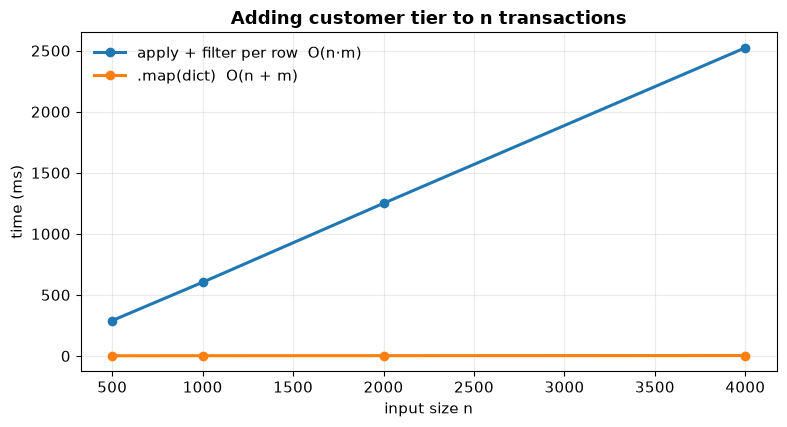

apply + filter: 0.631 ms per row at n = 4,000
-> 1,000,000 transactions would take at least 11 minutes (and more as m grows)
.map(dict) at n = 4,000: 3.50 ms in total


In [6]:
from dsa_kit import *

import random
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

def make_tables(n):
    rng = random.Random(n)
    customers = pd.DataFrame({"customer_id": range(n // 2),
                              "tier": [rng.choice(["bronze", "silver", "gold"]) for _ in range(n // 2)]})
    transactions = pd.DataFrame({"customer_id": [rng.randrange(n // 2) for _ in range(n)],
                                 "amount": [rng.randint(500, 50_000) for _ in range(n)]})
    return customers, transactions


def tier_with_apply_filter(tables):
    """For each row, filter the customers table: O(n · m)."""
    customers, transactions = tables
    return transactions["customer_id"].apply(
        lambda cid: customers.loc[customers["customer_id"] == cid, "tier"].iloc[0])


def tier_with_map(tables):
    """Build a dict once (hashing), then look each id up: O(n + m)."""
    customers, transactions = tables
    lookup = dict(zip(customers["customer_id"], customers["tier"]))
    return transactions["customer_id"].map(lookup)


tables = make_tables(1000)
assert tier_with_apply_filter(tables).equals(tier_with_map(tables))

sizes = [500, 1000, 2000, 4000]
results = benchmark({"apply + filter per row  O(n·m)": tier_with_apply_filter,
                     ".map(dict)  O(n + m)": tier_with_map},
                    make_input=make_tables, sizes=sizes, repeat=1)
plot_benchmark(sizes, results, title="Adding customer tier to n transactions")

per_row = results["apply + filter per row  O(n·m)"][-1] / sizes[-1]
print(f"apply + filter: {per_row * 1000:.3f} ms per row at n = {sizes[-1]:,}")
print(f"-> 1,000,000 transactions would take at least {per_row * 1_000_000 / 60:.0f} minutes (and more as m grows)")
print(f".map(dict) at n = {sizes[-1]:,}: {results['.map(dict)  O(n + m)'][-1] * 1000:.2f} ms in total")

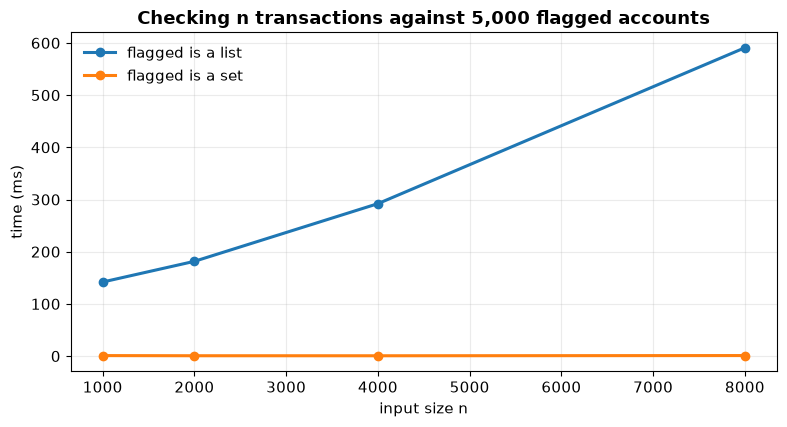

In [7]:
from dsa_kit import *

import random
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

def count_flagged_list(data):
    flagged, stream = data
    return sum(1 for account in stream if account in flagged)          # flagged is a list

def count_flagged_set(data):
    flagged, stream = data
    flagged_set = set(flagged)                                          # one-off O(m) build
    return sum(1 for account in stream if account in flagged_set)

def make_stream(n):
    rng = random.Random(n)
    flagged = [rng.randrange(10**7) for _ in range(5000)]
    stream = [rng.randrange(10**7) for _ in range(n)]
    return flagged, stream

sizes = [1000, 2000, 4000, 8000]
results = benchmark({"flagged is a list": count_flagged_list,
                     "flagged is a set": count_flagged_set},
                    make_input=make_stream, sizes=sizes, repeat=1)
plot_benchmark(sizes, results, title="Checking n transactions against 5,000 flagged accounts")

In [8]:
def unique_with_list(phones):
    seen = []
    for p in phones:
        if p not in seen:          # O(n) scan each time -> O(n²)
            seen.append(p)
    return seen

def unique_with_dict(phones):
    return list(dict.fromkeys(phones))   # hashing, keeps first-seen order -> O(n)

rng = random.Random(8)
phones = [f"080{rng.randint(0, 600_000):07d}" for _ in range(1_000_000)]

small = phones[:4000]
assert unique_with_list(small) == unique_with_dict(small)
t_small = time_it(unique_with_list, small, repeat=1)
t_dict = time_it(unique_with_dict, phones, repeat=1)
t_pandas = time_it(lambda: pd.Series(phones).drop_duplicates(), repeat=1)

estimate_hours = t_small * (len(phones) / len(small)) ** 2 / 3600
print(f"list-based, 4,000 numbers      : {t_small:.2f} s")
print(f"list-based, 1,000,000 numbers  : about {estimate_hours:.1f} hours (extrapolated as O(n²), not run!)")
print(f"dict.fromkeys, 1,000,000       : {t_dict:.2f} s")
print(f"pandas drop_duplicates, 1M     : {t_pandas:.2f} s")

list-based, 4,000 numbers      : 0.17 s
list-based, 1,000,000 numbers  : about 3.0 hours (extrapolated as O(n²), not run!)
dict.fromkeys, 1,000,000       : 0.62 s
pandas drop_duplicates, 1M     : 0.46 s


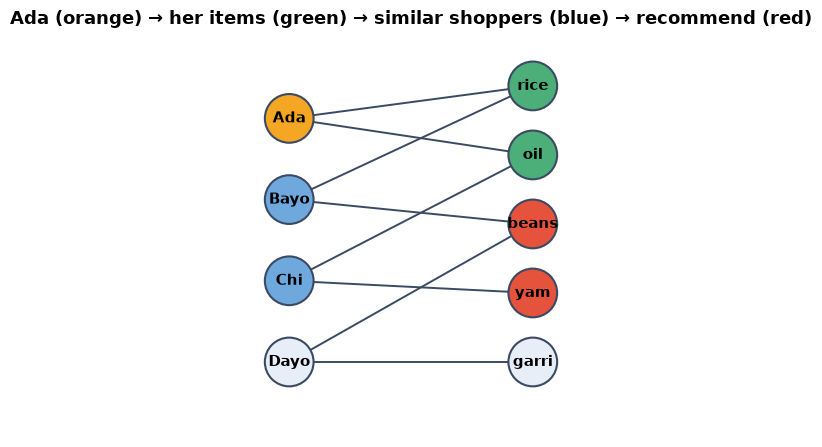

Similar shoppers: ['Bayo', 'Chi']   Recommend to Ada: ['beans', 'yam']


In [9]:
purchases = [("Ada", "rice"), ("Ada", "oil"), ("Bayo", "rice"), ("Bayo", "beans"),
             ("Chi", "oil"), ("Chi", "yam"), ("Dayo", "beans"), ("Dayo", "garri")]
customers = ["Ada", "Bayo", "Chi", "Dayo"]
products = ["rice", "oil", "beans", "yam", "garri"]
pos = {c: (0, 3 - i) for i, c in enumerate(customers)}
pos.update({p: (3, 3.4 - i * 0.85) for i, p in enumerate(products)})

# who bought what, and what did those people buy?
bought = {}
for person, item in purchases:
    bought.setdefault(person, set()).add(item)
ada_items = bought["Ada"]
neighbours = {p for p, items in bought.items() if p != "Ada" and items & ada_items}
recommend = set().union(*(bought[p] for p in neighbours)) - ada_items

colours = {"Ada": "active", **{p: "frontier" for p in neighbours}, **{i: "special" for i in recommend},
           **{i: "done" for i in ada_items}}
draw_graph(purchases, pos=pos, node_colors=colours, figsize=(7, 4.6),
           title="Ada (orange) → her items (green) → similar shoppers (blue) → recommend (red)")
print("Similar shoppers:", sorted(neighbours), "  Recommend to Ada:", sorted(recommend))

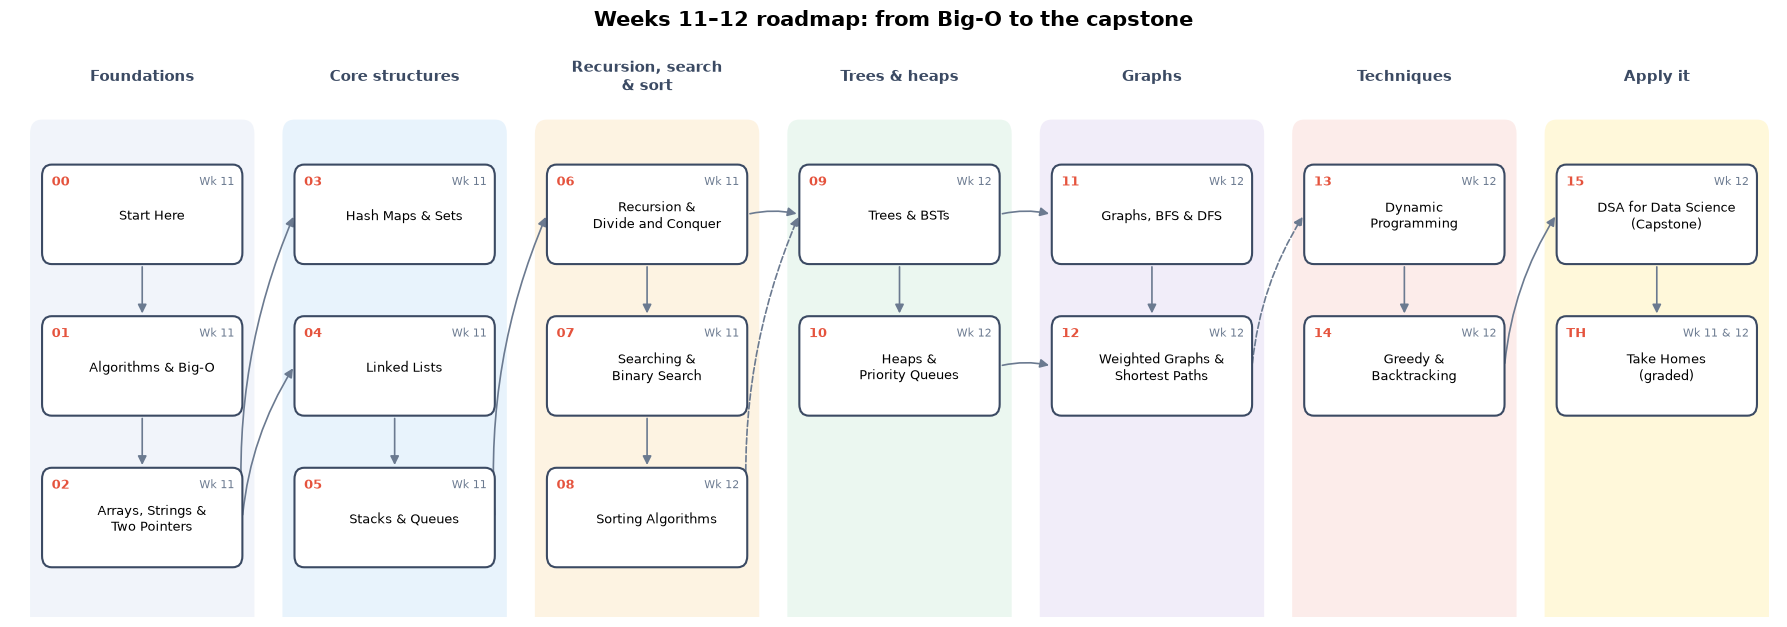

In [10]:
lessons = {
    "00": "Start Here",            "01": "Algorithms & Big-O",      "02": "Arrays, Strings &\nTwo Pointers",
    "03": "Hash Maps & Sets",      "04": "Linked Lists",            "05": "Stacks & Queues",
    "06": "Recursion &\nDivide and Conquer", "07": "Searching &\nBinary Search", "08": "Sorting Algorithms",
    "09": "Trees & BSTs",          "10": "Heaps &\nPriority Queues",
    "11": "Graphs, BFS & DFS",     "12": "Weighted Graphs &\nShortest Paths",
    "13": "Dynamic\nProgramming",  "14": "Greedy &\nBacktracking",
    "15": "DSA for Data Science\n(Capstone)", "TH": "Take Homes\n(graded)",
}
stages = [("Foundations", ["00", "01", "02"]), ("Core structures", ["03", "04", "05"]),
          ("Recursion, search\n& sort", ["06", "07", "08"]), ("Trees & heaps", ["09", "10"]),
          ("Graphs", ["11", "12"]), ("Techniques", ["13", "14"]), ("Apply it", ["15", "TH"])]
stage_colours = ["#E8EEF7", "#D9ECFB", "#FDEBD0", "#DFF3E7", "#E9E1F5", "#FBE0DC", "#FFF4C2"]
# solid arrows: "builds on". dashed arrows: "next in study order" (no direct dependency)
arrows = [("00", "01"), ("01", "02"), ("02", "03"), ("02", "04"), ("04", "05"), ("05", "06"),
          ("06", "07"), ("07", "08"), ("06", "09"), ("09", "10"), ("09", "11"),
          ("11", "12"), ("10", "12"), ("13", "14"), ("14", "15"), ("15", "TH")]
study_order = [("08", "09"), ("12", "13")]

box_w, box_h, col_gap, row_gap = 2.5, 1.05, 3.15, 1.6
pos = {}
fig, ax = plt.subplots(figsize=(18, 6.4))
for col, (stage, ids) in enumerate(stages):
    x = col * col_gap
    ax.add_patch(FancyBboxPatch((x - 0.15, -2 * row_gap - box_h - 0.25), box_w + 0.3, 2 * row_gap + box_h + 1.25,
                                boxstyle="round,pad=0,rounding_size=0.15", fc=stage_colours[col], ec="none", alpha=0.6))
    ax.text(x + box_w / 2, 1.45, stage, ha="center", va="center", fontsize=11, fontweight="bold", color="#3B4A63")
    for row, lid in enumerate(ids):
        y = -row * row_gap
        pos[lid] = (x, y)
        ax.add_patch(FancyBboxPatch((x, y - box_h / 2), box_w, box_h, boxstyle="round,pad=0,rounding_size=0.12",
                                    fc="white", ec=PALETTE["edge"], lw=1.5, zorder=3))
        ax.text(x + 0.12, y + box_h / 2 - 0.12, lid, ha="left", va="top", fontsize=9,
                color=PALETTE["special"], fontweight="bold", zorder=4)
        ax.text(x + box_w / 2 + 0.12, y - 0.02, lessons[lid], ha="center", va="center", fontsize=9.5, zorder=4)
        week = "Wk 11 & 12" if lid == "TH" else ("Wk 11" if lid <= "07" else "Wk 12")
        ax.text(x + box_w - 0.1, y + box_h / 2 - 0.12, week, ha="right", va="top", fontsize=8,
                color="#6b7a90", zorder=4)

for a, b in arrows + study_order:
    dashed = (a, b) in study_order
    (xa, ya), (xb, yb) = pos[a], pos[b]
    if xa == xb:      # same column: straight down
        start, end, style = (xa + box_w / 2, ya - box_h / 2), (xb + box_w / 2, yb + box_h / 2), "arc3,rad=0"
    else:             # next stage: right edge to left edge
        start, end, style = (xa + box_w, ya), (xb, yb), "arc3,rad=-0.12"
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=13, color="#6b7a90",
                                 lw=1.2, connectionstyle=style, zorder=2, linestyle="--" if dashed else "-"))

ax.set_xlim(-0.4, len(stages) * col_gap - 0.4)
ax.set_ylim(-2 * row_gap - box_h, 1.9)
ax.axis("off")
ax.set_title("Weeks 11–12 roadmap: from Big-O to the capstone", fontsize=15)
plt.tight_layout()
plt.show()

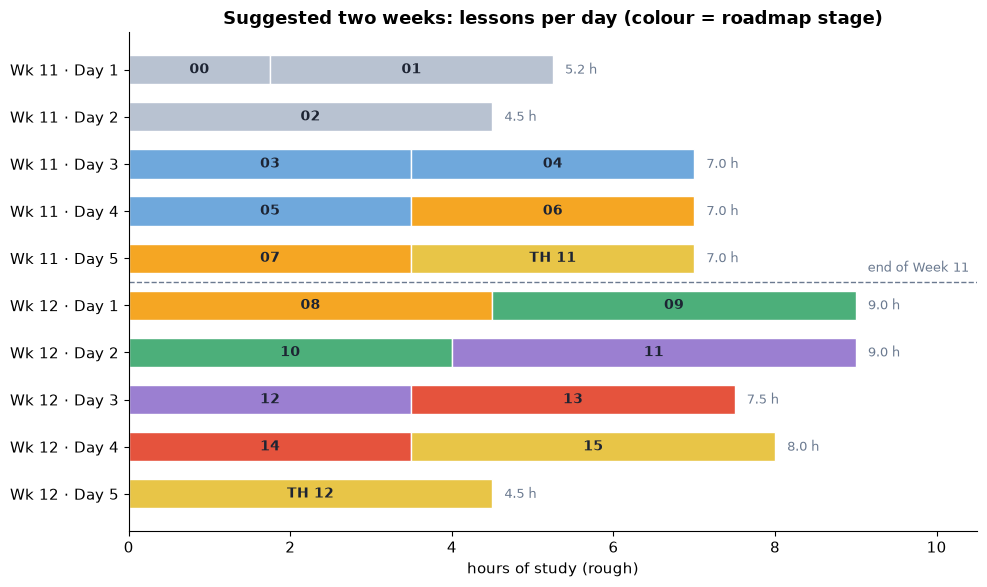

In [11]:
plan = {
    "Wk 11 · Day 1": [("00", 1.75), ("01", 3.5)],
    "Wk 11 · Day 2": [("02", 4.5)],
    "Wk 11 · Day 3": [("03", 3.5), ("04", 3.5)],
    "Wk 11 · Day 4": [("05", 3.5), ("06", 3.5)],
    "Wk 11 · Day 5": [("07", 3.5), ("TH 11", 3.5)],
    "Wk 12 · Day 1": [("08", 4.5), ("09", 4.5)],
    "Wk 12 · Day 2": [("10", 4.0), ("11", 5.0)],
    "Wk 12 · Day 3": [("12", 3.5), ("13", 4.0)],
    "Wk 12 · Day 4": [("14", 3.5), ("15", 4.5)],
    "Wk 12 · Day 5": [("TH 12", 4.5)],
}
stage_of = {"00": 0, "01": 0, "02": 0, "03": 1, "04": 1, "05": 1, "06": 2, "07": 2, "08": 2,
            "09": 3, "10": 3, "11": 4, "12": 4, "13": 5, "14": 5, "15": 6, "TH 11": 6, "TH 12": 6}
bar_colours = ["#B8C2D1", "#6FA8DC", "#F5A623", "#4CAF7A", "#9B7FD1", "#E5533D", "#E8C547"]

fig, ax = plt.subplots(figsize=(10, 6))
days = list(plan)
for d, day in enumerate(days):
    start = 0
    for lesson, hours in plan[day]:
        ax.barh(d, hours, left=start, color=bar_colours[stage_of[lesson]], edgecolor="white", height=0.62)
        ax.text(start + hours / 2, d, lesson, ha="center", va="center", fontsize=10, fontweight="bold",
                color="#1d2433")
        start += hours
    ax.text(start + 0.15, d, f"{start:.1f} h", va="center", fontsize=9, color="#6b7a90")
ax.axhline(4.5, color="#6b7a90", lw=1, ls="--")
ax.text(10.4, 4.35, "end of Week 11", ha="right", va="bottom", fontsize=9, color="#6b7a90")
ax.set_yticks(range(len(days)))
ax.set_yticklabels(days)
ax.invert_yaxis()
ax.set_xlabel("hours of study (rough)")
ax.set_xlim(0, 10.5)
ax.set_title("Suggested two weeks: lessons per day (colour = roadmap stage)")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

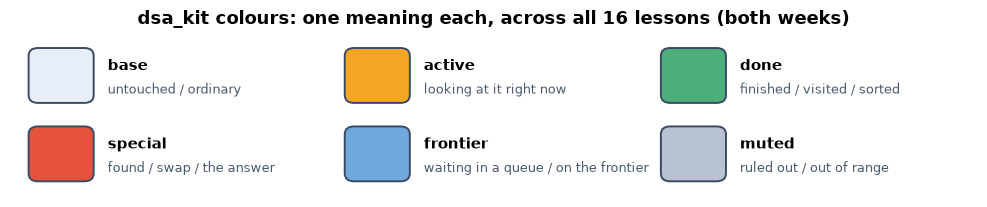

In [12]:
meanings = [("base", "untouched / ordinary"), ("active", "looking at it right now"),
            ("done", "finished / visited / sorted"), ("special", "found / swap / the answer"),
            ("frontier", "waiting in a queue / on the frontier"), ("muted", "ruled out / out of range")]

fig, ax = plt.subplots(figsize=(10, 2.2))
for i, (name, meaning) in enumerate(meanings):
    x = (i % 3) * 3.4
    y = 0 if i < 3 else -1
    ax.add_patch(FancyBboxPatch((x, y), 0.7, 0.7, boxstyle="round,pad=0,rounding_size=0.1",
                                fc=PALETTE[name], ec=PALETTE["edge"], lw=1.4))
    ax.text(x + 0.85, y + 0.47, name, fontsize=11, fontweight="bold", va="center")
    ax.text(x + 0.85, y + 0.17, meaning, fontsize=9, color="#4b5a70", va="center")
ax.set_xlim(-0.2, 10.2)
ax.set_ylim(-1.2, 0.9)
ax.axis("off")
ax.set_title("dsa_kit colours: one meaning each, across all 16 lessons (both weeks)")
plt.tight_layout()
plt.show()

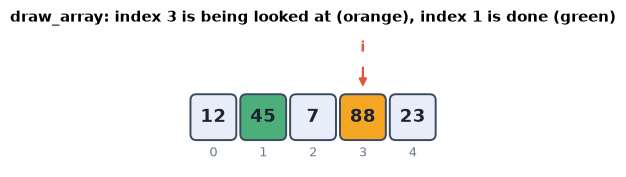

In [13]:
draw_array([12, 45, 7, 88, 23], highlight={1: "done", 3: "active"}, pointers={"i": 3},
           title="draw_array: index 3 is being looked at (orange), index 1 is done (green)")

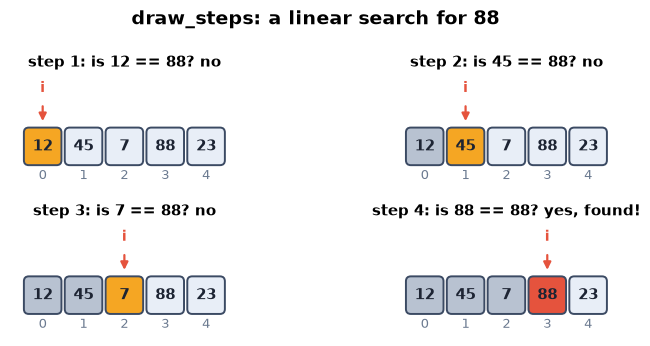

In [14]:
values = [12, 45, 7, 88, 23]
states = []
for i in range(4):
    found = values[i] == 88
    states.append({"values": values,
                   "highlight": {**{j: "muted" for j in range(i)}, i: "special" if found else "active"},
                   "pointers": {"i": i},
                   "caption": f"step {i + 1}: is {values[i]} == 88? {'yes, found!' if found else 'no'}"})
draw_steps(states, ncols=2, title="draw_steps: a linear search for 88")

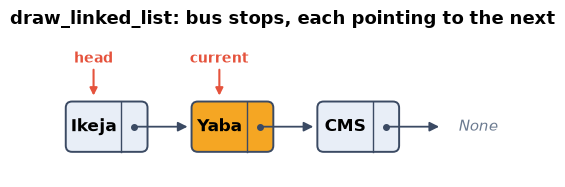

In [15]:
draw_linked_list(["Ikeja", "Yaba", "CMS"], highlight={1: "active"}, extra_pointers={"current": 1},
                 title="draw_linked_list: bus stops, each pointing to the next")

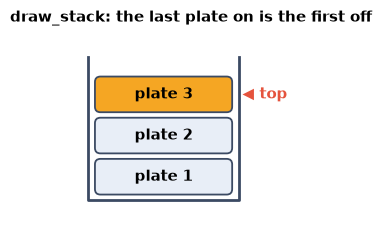

In [16]:
draw_stack(["plate 1", "plate 2", "plate 3"], title="draw_stack: the last plate on is the first off")


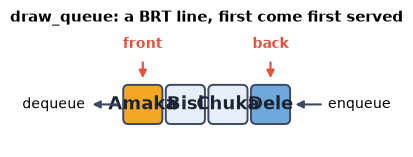

In [17]:
draw_queue(["Amaka", "Bisi", "Chuka", "Dele"], title="draw_queue: a BRT line, first come first served")


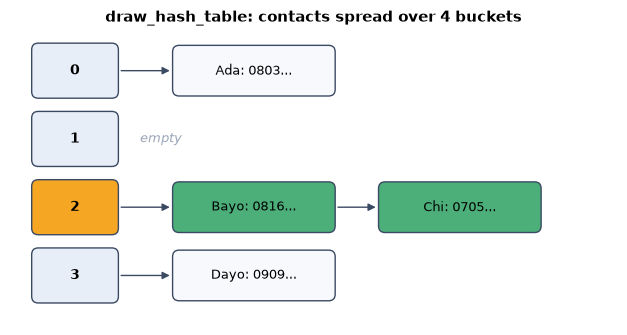

In [18]:
draw_hash_table([["Ada: 0803..."], [], ["Bayo: 0816...", "Chi: 0705..."], ["Dayo: 0909..."]],
                highlight_bucket=2, title="draw_hash_table: contacts spread over 4 buckets")

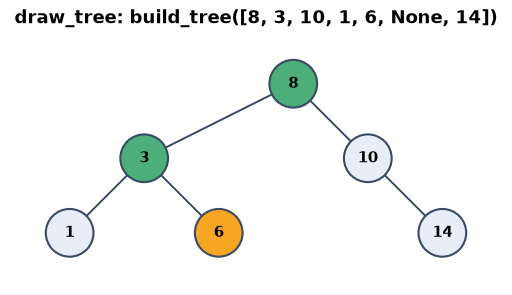

In [19]:
root = build_tree([8, 3, 10, 1, 6, None, 14])
draw_tree(root, highlight={6: "active", 8: "done", 3: "done"},
          title="draw_tree: build_tree([8, 3, 10, 1, 6, None, 14])")

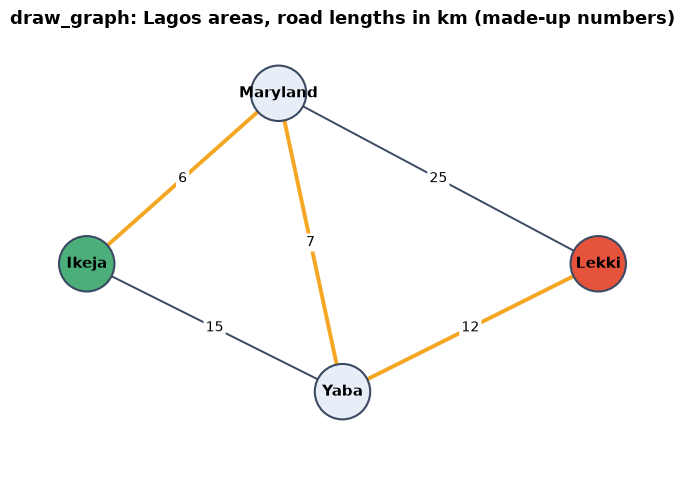

In [20]:
roads = [("Ikeja", "Maryland", 6), ("Maryland", "Yaba", 7), ("Ikeja", "Yaba", 15),
         ("Yaba", "Lekki", 12), ("Maryland", "Lekki", 25)]
lagos_pos = {"Ikeja": (-1.2, 0.0), "Maryland": (-0.3, 0.8), "Yaba": (0.0, -0.6), "Lekki": (1.2, 0.0)}
draw_graph(roads, pos=lagos_pos, figsize=(9, 5), node_colors={"Ikeja": "done", "Lekki": "special"},
           edge_colors={("Ikeja", "Maryland"): "active", ("Maryland", "Yaba"): "active",
                        ("Yaba", "Lekki"): "active"},
           title="draw_graph: Lagos areas, road lengths in km (made-up numbers)")

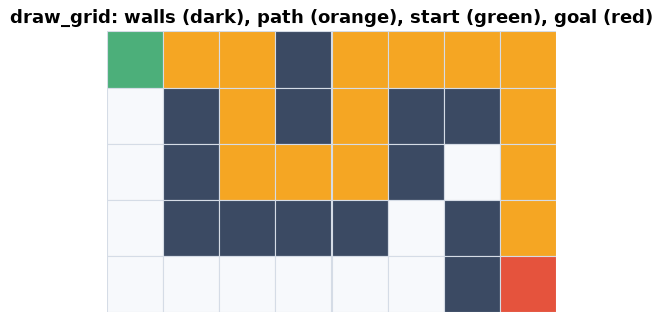

In [21]:
maze = ["S..#....",
        ".#.#.##.",
        ".#...#..",
        ".####.#.",
        "......#G"]
path = [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (1, 4), (0, 4), (0, 5), (0, 6), (0, 7),
        (1, 7), (2, 7), (3, 7), (4, 7)]
draw_grid(maze, path=path, start=(0, 0), goal=(4, 7), title="draw_grid: walls (dark), path (orange), start (green), goal (red)")

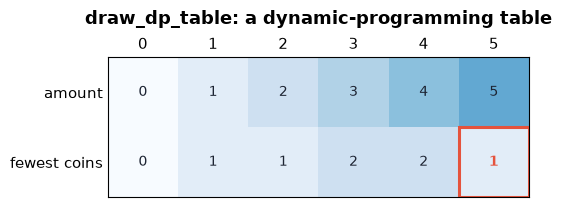

In [22]:
coin_table = [[0, 1, 2, 3, 4, 5],
              [0, 1, 1, 2, 2, 1]]
draw_dp_table(coin_table, row_labels=["amount", "fewest coins"], col_labels=[0, 1, 2, 3, 4, 5],
              highlight=[(1, 5)], title="draw_dp_table: a dynamic-programming table")

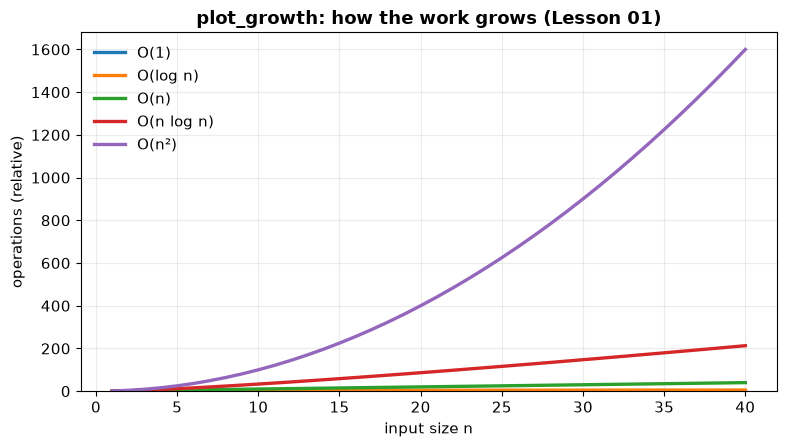

In [23]:
plot_growth(["O(1)", "O(log n)", "O(n)", "O(n log n)", "O(n²)"], n_max=40,
            title="plot_growth: how the work grows (Lesson 01)")

In [24]:
nums = random_list(100_000)          # 100,000 repeatable random ints
print("random_list(10) ->", random_list(10))
print(f"time_it(sorted, nums) -> {time_it(sorted, nums) * 1000:.2f} ms (best of 5 runs)")

random_list(10) -> [20, 3, 0, 23, 8, 7, 7, 4, 23, 3]
time_it(sorted, nums) -> 26.58 ms (best of 5 runs)


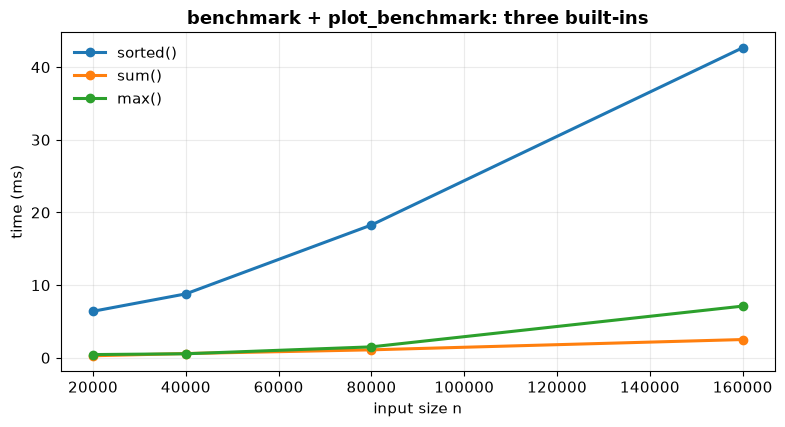

In [25]:
sizes = [20_000, 40_000, 80_000, 160_000]
results = benchmark({"sorted()": sorted, "sum()": sum, "max()": max},
                    make_input=random_list, sizes=sizes)
plot_benchmark(sizes, results, title="benchmark + plot_benchmark: three built-ins")

In [26]:
values = [5, 2, 8, 1, 9, 3, 7, 4]
frames = []
for i in range(len(values) - 1):
    hl = {i: "active", i + 1: "active"}
    swapped = values[i] > values[i + 1]
    if swapped:
        values[i], values[i + 1] = values[i + 1], values[i]
        hl = {i: "special", i + 1: "special"}
    frames.append({"values": list(values), "highlight": hl,
                   "caption": f"compare positions {i} and {i + 1}: " + ("swap!" if swapped else "keep")})
frames.append({"values": list(values), "highlight": {len(values) - 1: "done"},
               "caption": "after one pass, the largest value (9) is in its final place"})
animate_bars(frames, title="animate_bars: one pass of bubble sort", interval=600)

In [27]:
callout("Use <code>callout()</code> to show tips like this one.", kind="tip")
callout("…warnings like this one.", kind="warning")
callout("…and key ideas like this one.", kind="key")

In [28]:
def first_repeat_brute(ids):
    """For each position, look back at everything before it. Time O(n²), space O(1)."""
    for j in range(len(ids)):
        for i in range(j):
            if ids[i] == ids[j]:
                return ids[j]
    return None


def first_repeat(ids):
    """Walk once, remembering what we've seen. Time O(n) average, space O(n)."""
    seen = set()
    for tx_id in ids:
        if tx_id in seen:
            return tx_id
        seen.add(tx_id)
    return None

print(first_repeat(["T1", "T2", "T3", "T2", "T1"]))

T2


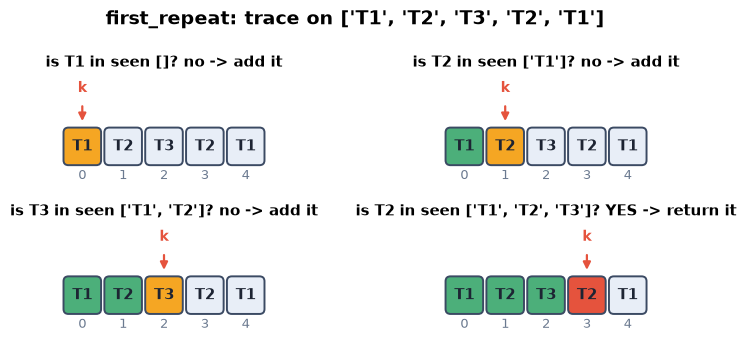

In [29]:
ids = ["T1", "T2", "T3", "T2", "T1"]
seen = set()
states = []
for k, tx_id in enumerate(ids):
    hit = tx_id in seen
    hl = {i: "done" for i in range(k)}
    hl[k] = "special" if hit else "active"
    states.append({"values": ids, "highlight": hl, "pointers": {"k": k},
                   "caption": f"is {tx_id} in seen {sorted(seen)}? " + ("YES -> return it" if hit else "no -> add it")})
    if hit:
        break
    seen.add(tx_id)
draw_steps(states, ncols=2, title="first_repeat: trace on ['T1', 'T2', 'T3', 'T2', 'T1']")

In [30]:
tests = [
    ((["T1", "T2", "T3", "T2", "T1"],), "T2"),
    ((["T1", "T2", "T3"],), None),
    (([],), None),
    ((["T7", "T7"],), "T7"),
    ((["A", "B", "B", "A"],), "B"),
]
check(first_repeat, tests)
check(first_repeat_brute, tests)

first_repeat: 🎉 All tests passed!
first_repeat_brute: 🎉 All tests passed!


True

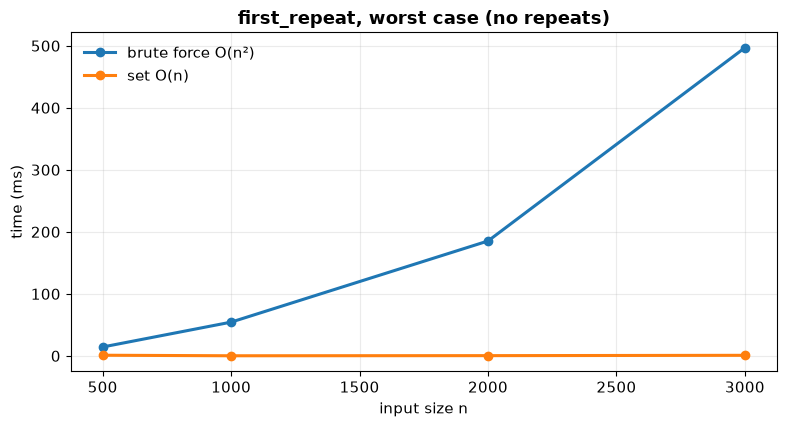

In [31]:
sizes = [500, 1000, 2000, 3000]
results = benchmark({"brute force O(n²)": first_repeat_brute, "set O(n)": first_repeat},
                    make_input=lambda n: [f"T{i}" for i in range(n)], sizes=sizes, repeat=1)
plot_benchmark(sizes, results, title="first_repeat, worst case (no repeats)")

In [32]:
def average(nums):
    """Mean of a list; 0 for an empty list."""
    return sum(nums) / len(nums)          # bug: divides by zero when nums is empty

average_tests = [(([2, 4, 6],), 4), (([5],), 5), (([],), 0), (([-1, 1],), 0)]
check(average, average_tests)

average: 3/4 tests passed
  ❌ average([],)
       expected 0
       got      'ZeroDivisionError: division by zero'


False

In [33]:
def average(nums):
    """Mean of a list; 0 for an empty list."""
    if not nums:
        return 0
    return sum(nums) / len(nums)

check(average, average_tests)

average: 🎉 All tests passed!


True

In [34]:
def not_done_yet(nums):
    raise NotImplementedError

check(not_done_yet, [(([1],), 1)])

⏳ not_done_yet: not implemented yet. Replace the `raise NotImplementedError` with your code.


False

In [35]:
def evens(nums):
    """All even numbers, in any order."""
    return [x for x in nums if x % 2 == 0][::-1]     # returns them reversed: still acceptable

check(evens, [(([1, 2, 3, 4],), [2, 4]), (([],), []), (([6, 8],), [6, 8])],
      compare=lambda got, expected: sorted(got) == sorted(expected), show_passing=True)

evens: 🎉 All tests passed!
  ✅ evens([1, 2, 3, 4],) -> [4, 2]
  ✅ evens([],) -> []
  ✅ evens([6, 8],) -> [8, 6]


True

In [37]:
def count_above(amounts, threshold):
    """How many amounts are > threshold.

    Time O(n): one pass. Space O(1).
    """
    count = 0
    for amount in amounts:
        if amount > threshold:
            count += 1
    return count


check(count_above, [
    (([5000, 12000, 800, 25000], 10000), 2),
    (([], 100), 0),
    (([100], 100), 0),
    (([101, 102], 100), 2),
    (([-5, -1, 0], -2), 2),
    (([7, 7, 7], 6), 3),
])

count_above: 🎉 All tests passed!


True

In [38]:
def largest(nums):
    """Largest value in nums, or None if empty.

    Time O(n): one pass. Space O(1).
    """
    if not nums:
        return None
    best = nums[0]
    for x in nums[1:]:
        if x > best:
            best = x
    return best


check(largest, [
    (([3, 9, 2],), 9),
    (([],), None),
    (([42],), 42),
    (([-7, -3, -10],), -3),
    (([5, 5, 5],), 5),
    (([0, -1, 1],), 1),
])

largest: 🎉 All tests passed!


True

In [39]:
def second_largest(sales):
    """Second-largest distinct value, or None.

    Time O(n): one pass, O(1) work per item. Space O(1).
    """
    best = None
    second = None
    for x in sales:
        if best is None or x > best:
            second = best          # the old best becomes second
            best = x
        elif x != best and (second is None or x > second):
            second = x
    return second


check(second_largest, [
    (([10, 40, 40, 30],), 30),
    (([],), None),
    (([5],), None),
    (([5, 5, 5],), None),
    (([1, 2],), 1),
    (([-3, -1, -2],), -2),
    (([7, 3, 9, 9, 8, 1],), 8),
])

second_largest: 🎉 All tests passed!


True